In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
def f(x):
    return 3*x**2 - 4*x + 5

In [3]:
f(3.0)

20.0

[-5.   -4.75 -4.5  -4.25 -4.   -3.75 -3.5  -3.25 -3.   -2.75 -2.5  -2.25
 -2.   -1.75 -1.5  -1.25 -1.   -0.75 -0.5  -0.25  0.    0.25  0.5   0.75
  1.    1.25  1.5   1.75  2.    2.25  2.5   2.75  3.    3.25  3.5   3.75
  4.    4.25  4.5   4.75]
[100.      91.6875  83.75    76.1875  69.      62.1875  55.75    49.6875
  44.      38.6875  33.75    29.1875  25.      21.1875  17.75    14.6875
  12.       9.6875   7.75     6.1875   5.       4.1875   3.75     3.6875
   4.       4.6875   5.75     7.1875   9.      11.1875  13.75    16.6875
  20.      23.6875  27.75    32.1875  37.      42.1875  47.75    53.6875]


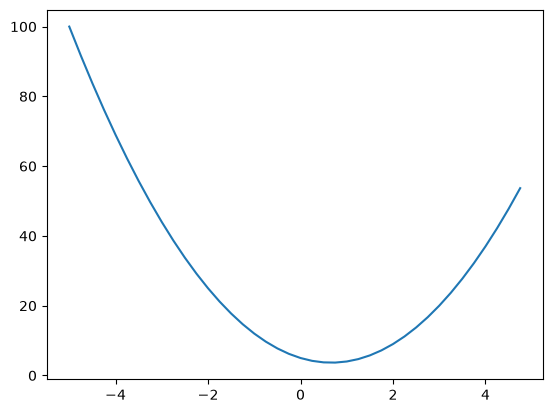

In [4]:
xs = np.arange(-5, 5, 0.25)
print(xs)
ys = f(xs)
print(ys)
plt.plot(xs, ys)

In [5]:
h = 0.00000001
x = 3.0
(f(x + h) - f(x)) / h

14.00000009255109

In [6]:
# let's get more complex
a = 2.0
b = -3.0
c = 10.0
d = a*b + c
print(d)

4.0


In [7]:
# we need to see how d changes according to a, b, and c, respectively
h = 0.0001

# inputs
a = 2.0
b = -3.0
c = 10.0

d1 = a*b + c
print('d1', d1)

a += h
d2 = a*b + c
print('d2', d2)
print('slope d2->d1', (d2 - d1) / h)
a -= h

b += h
d3 = a*b + c
print('d3', d3)
print('slope d3->d1', (d3 - d1) / h)
b -= h

c += h
d4 = a*b + c
print('d4', d4)
print('slope d4->d1', (d4 - d1) / h)
c -= h

d1 4.0
d2 3.999699999999999
slope d2->d1 -3.000000000010772
d3 4.0002
slope d3->d1 2.0000000000042206
d4 4.0001
slope d4->d1 0.9999999999976694


In [306]:
class Value:

    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self.grad = 0.0
        self._backward = lambda: None
        self._prev = set(_children)
        self._op = _op
        self.label = label

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other) # to support "a + 1"
        out = Value(self.data + other.data, (self, other), '+')

        def _backward():
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad
        out._backward = _backward
        return out

    def __radd__(self, other):
        return self + other
    
    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other) # to support "a * 2"
        out = Value(self.data * other.data, (self, other), '*')

        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
        out._backward = _backward
        return out

    def __rmul__(self, other): # other * self, like 2 * a
        return self * other

    def __pow__(self, other):
        assert isinstance(other, (int, float)), "only support int/float powers for now"
        out = Value(self.data**other, (self, ), f'**{other}')

        def _backward():
            self.grad += other * self.data**(other - 1) * out.grad
        out._backward = _backward
        return out
    
    def __truediv__(self, other): # self / other
        return self * other**-1 # a/b == a * (1/b) == a * (b**-1)

    def __neg__(self):
        return self * -1

    def __sub__(self, other): # self - other
        return self + (-other)
    
    def tanh(self):
        x = self.data
        t = (math.exp(2*x) - 1)/(math.exp(2*x) + 1)
        out = Value(t, (self, ), 'tanh')

        def _backward():
            self.grad += (1 - t**2) * out.grad
        out._backward = _backward
        return out

    def exp(self):
        x = self.data
        out = Value(math.exp(x), (self, ), 'exp')

        def _backward():
            self.grad += out.data * out.grad
        out._backward = _backward
        return out
    
    def backward(self):
        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)

        self.grad = 1.0
        for node in reversed(topo):
            node._backward()

a = Value(2.0, label='a')
b = Value(-3.0, label='b')
c = Value(10.0, label='c')
print(a + b) # a.__add__(b) internally
print(a * b)
print(a * b + c) # (a.__mul__(b)).__add__(c)

e = a * b
e.label = 'e'
d = e + c
d.label = 'd'
print(d._prev)
print(d._op)

f = Value(-2.0, label='f')
L = d * f
L.label = 'L'
L

Value(data=-1.0)
Value(data=-6.0)
Value(data=4.0)
{Value(data=10.0), Value(data=-6.0)}
+


Value(data=-8.0)

Most important part: how to derive dL / dc?
How does L change with respective to c, through d?
Intuition: we know how c impacts d, and then how d impacts L, so we should be able to put it together to derive how c impacts L.

d = c + e
dd / dc == 1.0
dd / de == 1.0

Chain rule in calculus
dz/dx = (dz/dy) * (dy/dx)
h'(x) = f'(g(x))g'(x)

so,
dL / dc = (dL / dd) * (dd / dc) = -2.0 * 1.0 = -2.0
dL / de = (dL / dd) * (dd / de) = -2.0 * 1.0 = -2.0

similarly,
dL / da = (dL / de) * (de / da) = -2.0 * (-3.0) = 6.0
dL / db = (dL / de) * (de / db) = -2.0 * (2.0) = -4.0

In [307]:
# grad means how L changes according to the node
L.grad = 1.0 # this is how L changes with respect to L
f.grad = 4.0
d.grad = -2.0
c.grad = -2.0
e.grad = -2.0
b.grad = -4.0
a.grad = 6.0

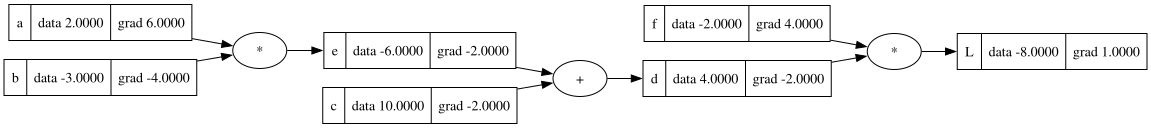

In [308]:
from graphviz import Digraph

def trace(root):
    # builds a set of all nodes and edges in a graph
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'}) # LR = left to right

    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        # for any value in the graph, create a rectangular ('record') node for it
        dot.node(name = uid, label = "{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape='record')
        if n._op:
            # if this value is a result of some operation, create an op node for it
            dot.node(name = uid + n._op, label = n._op)
            # and connect this node to it
            dot.edge(uid + n._op, uid)

    for n1, n2 in edges:
        # connect n1 to the op node of n2
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot

draw_dot(L)

In [309]:
# verification
def lol():
    h = 0.0001

    a = Value(2.0, label='a')
    b = Value(-3.0, label='b')
    c = Value(10.0, label='c')
    e = a * b; e.label = 'e'
    d = e + c; d.label = 'd'
    f = Value(-2.0, label='f')
    L = d * f; L.label = 'L'
    L1 = L.data

    a = Value(2.0, label='a')
    b = Value(-3.0 + h, label='b')
    c = Value(10.0, label='c')
    e = a * b; e.label = 'e'
    d = e + c; d.label = 'd'
    f = Value(-2.0, label='f')
    L = d * f; L.label = 'L'
    L2 = L.data
    print((L2 - L1) / h)

lol()

-4.000000000008441


In [310]:
# So, let's see the forward pass impact
# each leaf variable moves a bit toward its gradient to make L better
a.data += 0.01 * a.grad
b.data += 0.01 * b.grad
c.data += 0.01 * c.grad
f.data += 0.01 * f.grad

e = a * b
d = e + c
L = d * f
L


Value(data=-7.286496)

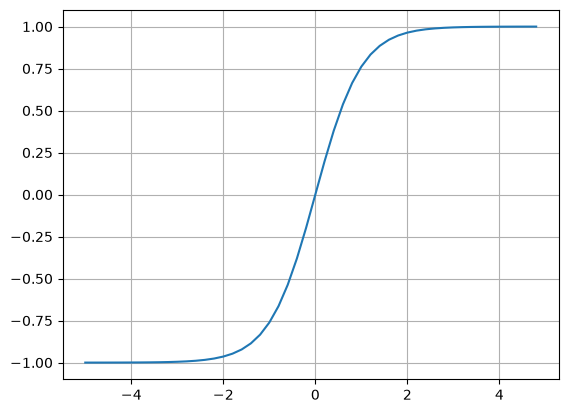

In [311]:
# An activation function:
plt.plot(np.arange(-5, 5, 0.2), np.tanh(np.arange(-5, 5, 0.2))); plt.grid();

In [312]:
# now move on to neuron
# inputs x1,x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
# weights w1, w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
# bias of the neuron
b = Value(6.8813735870195432, label='b') # magic number to make our result beautiful
# x1*w1 + x2*w2 + b
x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 * x2*w2'
n = x1w1x2w2 + b; n.label = 'n'
o = n.tanh(); o.label = 'o'

In [313]:
# Manual version
# o.grad = 1.0

# # o = tanh(n)
# # do/dn = 1 - tanh(n)**2 = 1 - o**2
# # n.grad = 1 - o.data**2 0.4999999999999999
# n.grad = 0.5

# x1w1x2w2.grad = 0.5
# b.grad = 0.5

# x1w1.grad = 0.5
# x2w2.grad = 0.5

# x1.grad = 0.5 * w1.data
# w1.grad = 0.5 * x1.data
# x2.grad = 0.5 * w2.data
# w2.grad = 0.5 * x2.data # It's 0.0, because x2 is 0.0, w2 change does not have any effect!

In [314]:
# # Manual-backward version!
# o.grad = 1.0
# o._backward()
# n._backward()
# x1w1x2w2._backward()
# b._backward() # should be none
# x1w1._backward()
# x2w2._backward()

In [315]:
# It's the topo order
topo = []
visited = set()
def build_topo(v):
    if v not in visited:
        visited.add(v)
        for child in v._prev:
            build_topo(child)
        topo.append(v)
build_topo(o)
topo

[Value(data=6.881373587019543),
 Value(data=1.0),
 Value(data=0.0),
 Value(data=0.0),
 Value(data=-3.0),
 Value(data=2.0),
 Value(data=-6.0),
 Value(data=-6.0),
 Value(data=0.8813735870195432),
 Value(data=0.7071067811865476)]

In [316]:

# Auto-backward version!!
# o.grad = 1.0
# for node in reversed(topo):
#     node._backward()
o.backward()

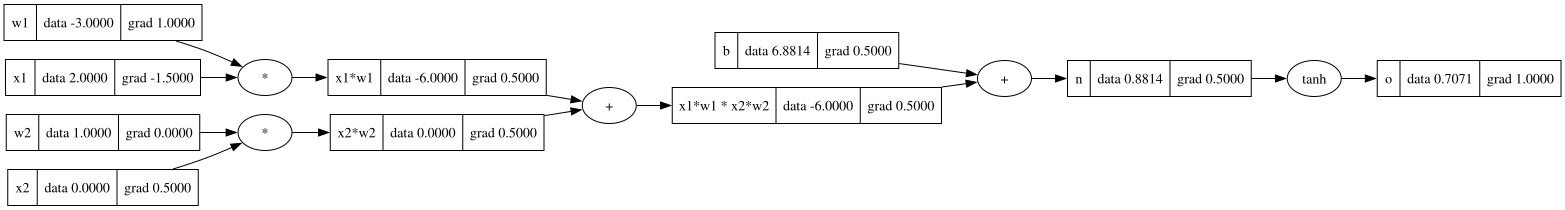

In [317]:
draw_dot(o)

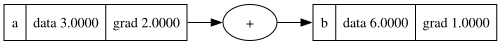

In [318]:
# There is an error with existing impl:
a = Value(3.0, label='a')
b = a + a; b.label = 'b'
b.backward()
draw_dot(b)
# a.grad should be 2, but output is 1
# the assumption is that self and other are different
# but in this example, self and other are the same, a

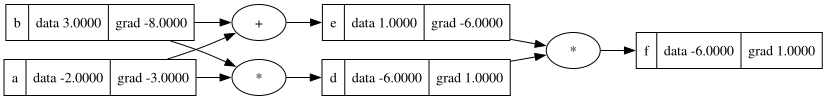

In [319]:
# Another wrong example:
a = Value(-2.0, label='a')
b = Value(3.0, label='b')
d = a * b; d.label = 'd'
e = a + b; e.label = 'e'
f = d * e; f.label = 'f'
f.backward()
draw_dot(f)
# in this example, a and b are used more than once
# a and b's effect and e and d is not accumulated, but overridden
# The fix is to change _backward() function to PLUS the grad!

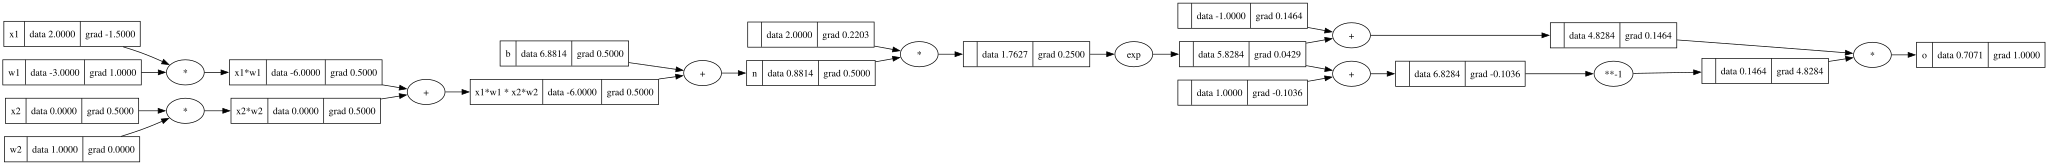

In [320]:
# now same expressions, except how we define o
# replace tanh with exp and div
# inputs x1,x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
# weights w1, w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
# bias of the neuron
b = Value(6.8813735870195432, label='b') # magic number to make our result beautiful
# x1*w1 + x2*w2 + b
x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 * x2*w2'
n = x1w1x2w2 + b; n.label = 'n'
# --- changing here!
e = (2 * n).exp()
o = (e - 1) / (e + 1)
# ---
o.label = 'o'
o.backward()
draw_dot(o)

In [321]:
# We can do all above with pytorch
import torch
x1 = torch.Tensor([2.0]).double(); x1.requires_grad = True
x2 = torch.Tensor([0.0]).double(); x2.requires_grad = True
w1 = torch.Tensor([-3.0]).double(); w1.requires_grad = True
w2 = torch.Tensor([1.0]).double(); w2.requires_grad = True
b = torch.Tensor([6.8813735870195432]).double(); b.requires_grad = True
n = x1 * w1 + x2 * w2 + b
o = torch.tanh(n)

print(o.data.item())
o.backward()

print('x2', x2.grad.item())
print('w2', w2.grad.item())
print('x1', x1.grad.item())
print('w1', w1.grad.item())

0.7071066904050358
x2 0.5000001283844369
w2 0.0
x1 -1.5000003851533106
w1 1.0000002567688737


In [411]:
import random

class Neuron:

    def __init__(self, nin): # nin: how many inputs coming to the neuron
        self.w = [Value(random.uniform(-1, 1)) for _ in range(nin)]
        self.b = Value(random.uniform(-1, 1))

    def __call__(self, x): # we can now call n = Neuron(2); n(x)
        # w * x + b
        act = sum((wi * xi for wi, xi in zip(self.w, x)), self.b)
        out = act.tanh()
        return out

    def parameters(self):
        return self.w + [self.b]

class Layer:

    def __init__(self, nin, nout):
        self.neurons = [Neuron(nin) for _ in range(nout)]

    def __call__(self, x):
        outs = [n(x) for n in self.neurons]
        return outs[0] if len(outs) == 1 else outs

    def parameters(self):
        return [p for neuron in self.neurons for p in neuron.parameters()]
        # params = []
        # for neuron in self.neurons:
        #     ps = neuron.parameters()
        #     params.extend(ps)
        # return params

class MLP: # Multilayer Perceptron

    def __init__(self, nin, nouts): # list of nouts, sz for each layer
        sz = [nin] + nouts
        self.layers = [Layer(sz[i], sz[i + 1]) for i in range(len(nouts))]

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        return x

    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]

x = [2.0, 3.0, -1]
n = MLP(3, [4, 4, 1])
n(x)


Value(data=-0.9944382033418941)

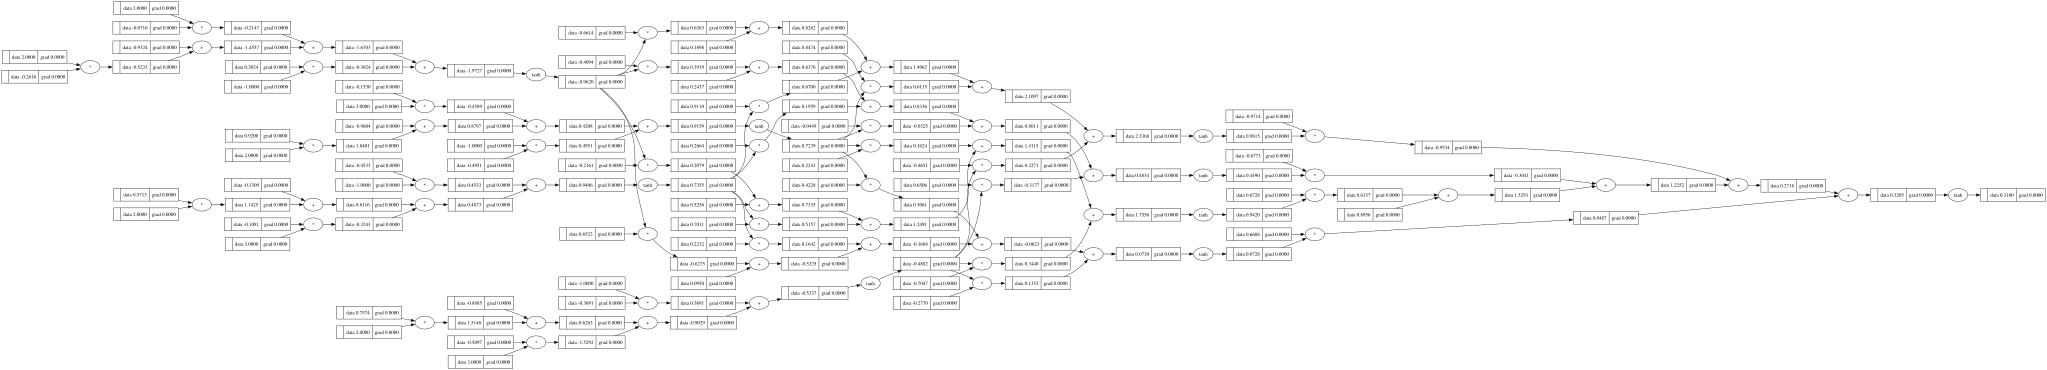

In [334]:
draw_dot(n(x))

In [412]:
xs = [
    [2.0, 3.0, -1.0],
    [3.0, -1.0, 0.5],
    [0.5, 1.0, 1.0],
    [1.0, 1.0, -1.0],
]
ys = [1.0, -1.0, -1.0, 1.0] # desired targets
# we want ypred to in the end close to ys, for each x in xs, predict the desired y in ys
ypred = [n(x) for x in xs]
ypred

[Value(data=-0.9944382033418941),
 Value(data=-0.9947603095871523),
 Value(data=-0.9191300266619185),
 Value(data=-0.9942341034146887)]

In [350]:
loss = sum([(yout - ygt)**2 for ygt, yout in zip(ys, ypred)])
loss

Value(data=5.1807063348821405)

In [394]:
loss.backward()

In [395]:
print(n.layers[0].neurons[0].w[0].grad, n.layers[0].neurons[0].w[0].data)

6.7801536376552 -0.7301813052625067


In [396]:
len(n.parameters())

41

In [397]:
for p in n.parameters():
    p.data += -0.01 * p.grad # move against its gradient to MINIMIZE the loss

In [398]:
print(n.layers[0].neurons[0].w[0].grad, n.layers[0].neurons[0].w[0].data)

6.7801536376552 -0.7979828416390586


In [ ]:
# recalculate loss, this is the forward pass
ypred = [n(x) for x in xs]
loss = sum([(yout - ygt)**2 for ygt, yout in zip(ys, ypred)])
loss

Value(data=0.9161816139194047)

In [413]:
for k in range(20):
    # gradient descent

    # forward pass
    ypred = [n(x) for x in xs]
    loss = sum([(yout - ygt)**2 for ygt, yout in zip(ys, ypred)])

    # backward pass
    for p in n.parameters(): # This is tricky bug! We need to zero-grad before backward()!!
        p.grad = 0.0
    loss.backward()

    # update
    for p in n.parameters():
        p.data += -0.05 * p.grad

    print(k, loss.data)

print(ypred)

0 7.9613208131151545
1 7.959637456063259
2 7.957803068924577
3 7.955795621124124
4 7.953588549764017
5 7.9511495140022985
6 7.948438709585486
7 7.945406548453535
8 7.941990401338223
9 7.938109922457207
10 7.933660166179807
11 7.928501149497182
12 7.922441468119668
13 7.915211500006862
14 7.906417354595386
15 7.895456784903283
16 7.88135357000372
17 7.862398246187893
18 7.835263783634883
19 7.792425008813483
[Value(data=-0.9679384744379511), Value(data=-0.9853980596179556), Value(data=-0.8412457391274473), Value(data=-0.9733795979568153)]
